In [41]:
import os
import sys
sys.path.append("..")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.preprocessing import LabelEncoder

from src.data_prep import clean_data, load_data, time_split
from src.evaluate import (PARAM_GRIDS, RANDOM_STATE, compare_models, get_models,
                          make_pipeline, score_on_test)
from src.features import add_time_features

sns.set_theme(style="whitegrid")
FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("../models", exist_ok=True)
CLASS_ORDER = ["Light_Load", "Medium_Load", "Maximum_Load"]

## 2. Loading and inspecting the raw data

The dataset has one row every 15 minutes for the whole of 2018 (35,040 readings plus one extra row).

| Column | Meaning | Unit |
|---|---|---|
| `Date_Time` | Timestamp (renamed to `Date` on load) | dd-mm-yyyy HH:MM |
| `Usage_kWh` | Industry energy consumption | kWh |
| `Lagging_Current_Reactive.Power_kVarh` | Lagging reactive power | kVarh |
| `Leading_Current_Reactive_Power_kVarh` | Leading reactive power | kVarh |
| `CO2(tCO2)` | CO2 emissions | tCO2 |
| `Lagging_Current_Power_Factor` / `Leading_Current_Power_Factor` | Power factor (valid range 0 to 100) | % |
| `NSM` | Number of seconds from midnight | s |
| `Load_Type` | **Target**: Light, Medium or Maximum load | category |

In [42]:
raw = load_data("../data/raw/load_data.csv")
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 35,041 | Columns: 9


,Date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [43]:
missing = raw.isnull().sum().to_frame("missing")
missing["% missing"] = (missing["missing"] / len(raw) * 100).round(2)
missing

,missing,% missing
Date,0,0.00
Usage_kWh,1559,4.45
Lagging_Current_Reactive.Power_kVarh,876,2.50
Leading_Current_Reactive_Power_kVarh,1156,3.30
CO2(tCO2),455,1.30
Lagging_Current_Power_Factor,350,1.00
Leading_Current_Power_Factor,1471,4.20
NSM,455,1.30
Load_Type,0,0.00


In [44]:
ts = pd.to_datetime(raw["Date"], format="%d-%m-%Y %H:%M", errors="coerce")
expected_nsm = ts.dt.hour * 3600 + ts.dt.minute * 60
nsm = pd.to_numeric(raw["NSM"], errors="coerce")
lag_pf = pd.to_numeric(raw["Lagging_Current_Power_Factor"], errors="coerce")
lead_pf = pd.to_numeric(raw["Leading_Current_Power_Factor"], errors="coerce")

quality = pd.Series({
    "Timestamps that fail to parse": int(ts.isna().sum()),
    "Duplicate timestamps": int(ts.duplicated().sum()),
    "NSM values that disagree with the timestamp": int(((nsm != expected_nsm) & nsm.notna()).sum()),
    "Lagging power factor above 100": int((lag_pf > 100).sum()),
    "Leading power factor above 100": int((lead_pf > 100).sum()),
}).to_frame("count")
quality

,count
Timestamps that fail to parse,0
Duplicate timestamps,1
NSM values that disagree with the timestamp,3414
Lagging power factor above 100,3226
Leading power factor above 100,2685


In [45]:
# A few examples of corrupted NSM values next to the value implied by the timestamp
bad_nsm = raw.assign(expected_NSM=expected_nsm)[(nsm != expected_nsm) & nsm.notna()]
bad_nsm[["Date", "NSM", "expected_NSM"]].head(5)

,Date,NSM,expected_NSM
2,01-01-2018 00:45,8070.880991,2700
7,01-01-2018 02:00,16589.736453,7200
13,01-01-2018 03:30,36574.178080,12600
14,01-01-2018 03:45,35294.963036,13500
38,01-01-2018 09:45,85881.718202,35100


In [46]:
df = clean_data(raw)
rebuilt_ok = (df["NSM"] == df["Date"].dt.hour * 3600 + df["Date"].dt.minute * 60).all()

print(f"Rows before: {len(raw):,} | after: {len(df):,} ({len(raw) - len(df)} duplicate timestamp removed)")
print(f"NSM now consistent with the timestamp: {bool(rebuilt_ok)}")
print(f"Date range: {df['Date'].min()}  ->  {df['Date'].max()}")
df["Date"].dt.to_period("M").value_counts().sort_index().to_frame("rows")

Rows before: 35,041 | after: 35,040 (1 duplicate timestamp removed)
NSM now consistent with the timestamp: True
Date range: 2018-01-01 00:00:00  ->  2018-12-31 23:45:00


,rows
Date,
2018-01,2976
2018-02,2688
2018-03,2976
2018-04,2880
2018-05,2976
2018-06,2880
2018-07,2976
2018-08,2976
2018-09,2880


,% of rows
Load_Type,
Light_Load,51.6
Medium_Load,27.7
Maximum_Load,20.8


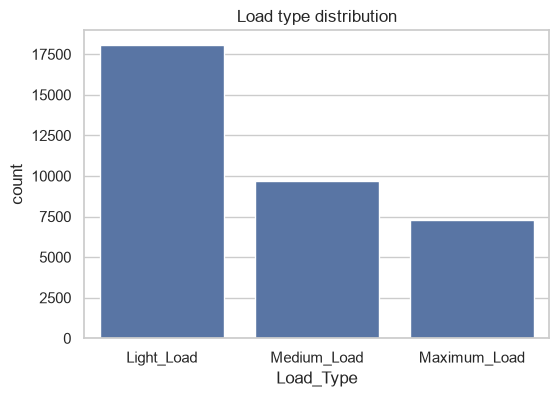

In [47]:
share = df["Load_Type"].value_counts(normalize=True).reindex(CLASS_ORDER).mul(100).round(1)
display(share.to_frame("% of rows"))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Load_Type", order=CLASS_ORDER, ax=ax)
ax.set_title("Load type distribution")
fig.savefig(f"{FIG_DIR}/class_distribution.png", bbox_inches="tight")
plt.show()

**Insight:** Light Load makes up about 52% of readings, Medium about 28% and Maximum about 21%. The imbalance is moderate, but it means accuracy alone can flatter a model. We therefore track **macro-averaged precision, recall and F1** and use class weights where the model supports them.

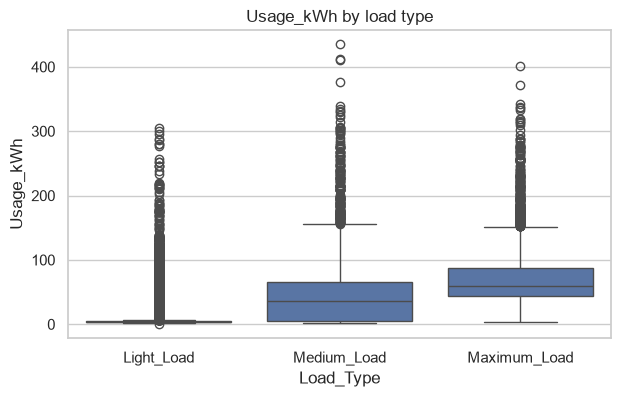

,median kWh
Load_Type,
Light_Load,3.4
Medium_Load,35.9
Maximum_Load,58.9


In [48]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="Load_Type", y="Usage_kWh", order=CLASS_ORDER, ax=ax)
ax.set_title("Usage_kWh by load type")
fig.savefig(f"{FIG_DIR}/usage_by_load.png", bbox_inches="tight")
plt.show()

df.groupby("Load_Type")["Usage_kWh"].median().reindex(CLASS_ORDER).round(1).to_frame("median kWh")

**Insight:** Median usage rises from about 3 kWh (Light) to about 36 kWh (Medium) and 59 kWh (Maximum), so usage is clearly related to the label. The classes still **overlap heavily**: Medium has a wide spread and many low-usage readings, and all three classes have long upper tails. Usage alone will not separate them cleanly, so a model needs more context such as the time of day.

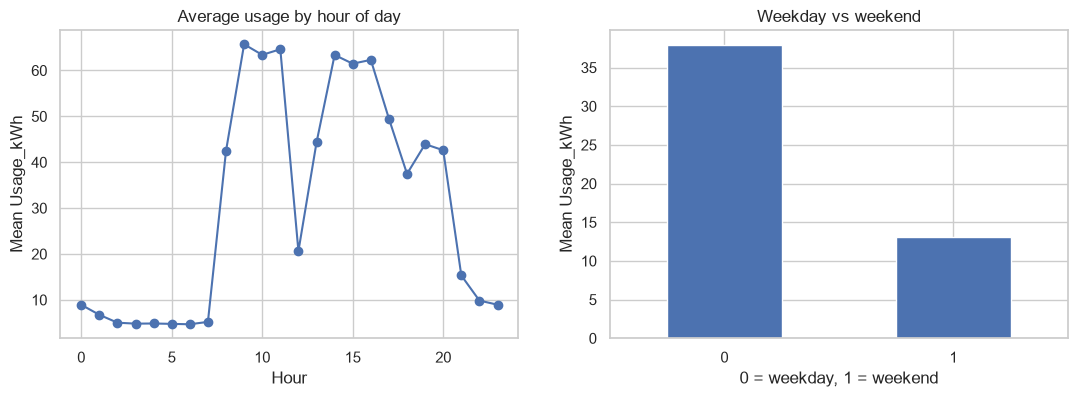

In [49]:
eda = df.assign(hour=df["Date"].dt.hour,
                is_weekend=(df["Date"].dt.day_of_week >= 5).astype(int))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
eda.groupby("hour")["Usage_kWh"].mean().plot(ax=ax[0], marker="o")
ax[0].set(title="Average usage by hour of day", xlabel="Hour", ylabel="Mean Usage_kWh")
eda.groupby("is_weekend")["Usage_kWh"].mean().plot(kind="bar", ax=ax[1], rot=0)
ax[1].set(title="Weekday vs weekend", xlabel="0 = weekday, 1 = weekend", ylabel="Mean Usage_kWh")
fig.savefig(f"{FIG_DIR}/time_patterns.png", bbox_inches="tight")
plt.show()

**Insight:**
- The plant runs on a clear daily cycle. Usage is low (about 5 kWh) from 02:00 to 07:59, jumps sharply at 08:00, stays high through the working day with a dip at 12:00 (probably a lunch break), and falls after 21:00.
- Weekends use about a third as much energy as weekdays (about 13 vs 38 kWh on average).

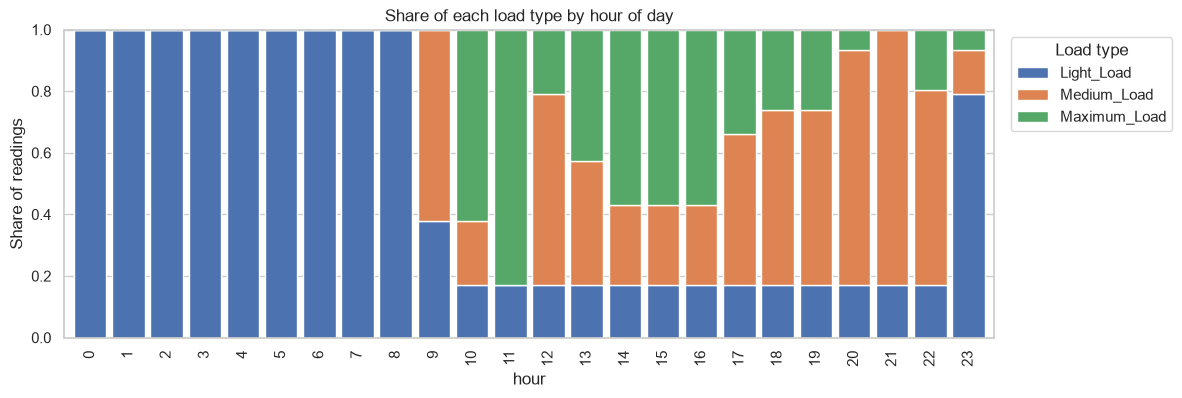

In [50]:
mix = pd.crosstab(eda["hour"], eda["Load_Type"], normalize="index")[CLASS_ORDER]
mix.plot(kind="bar", stacked=True, figsize=(12, 4), width=0.85)
plt.title("Share of each load type by hour of day")
plt.ylabel("Share of readings")
plt.legend(title="Load type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.savefig(f"{FIG_DIR}/load_mix_by_hour.png", bbox_inches="tight")
plt.show()

**Insight:** Time of day strongly structures the label.
- From midnight to 08:59, every reading is Light Load.
- **Maximum Load** concentrates between about 10:00 and 17:00, peaking around 11:00.
- **Medium Load** dominates the evening (18:00 to 22:00).
- Around 17% of readings stay Light Load even during the working day. These come mostly from **Sundays** (about two-thirds of Sunday daytime readings are Light), while Saturdays are mixed. Weekdays are almost never Light between 10:00 and 21:00.

So time of day and day of the week should be strong predictors.

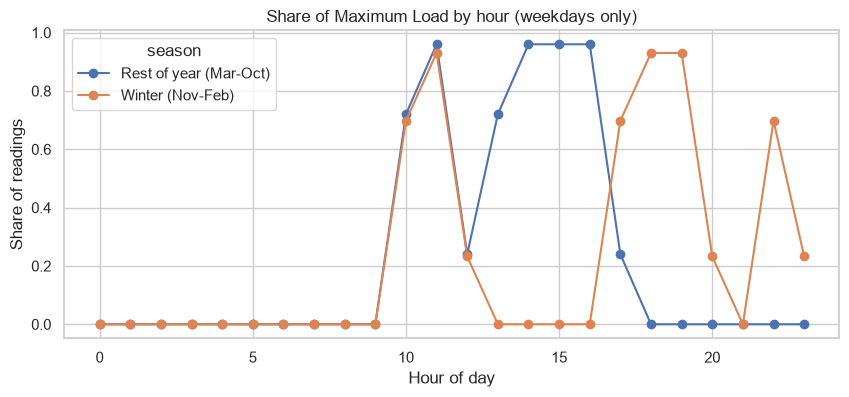

In [51]:
wk = eda[eda["Date"].dt.day_of_week < 5].copy()
wk["season"] = np.where(wk["Date"].dt.month.isin([11, 12, 1, 2]), "Winter (Nov-Feb)", "Rest of year (Mar-Oct)")
wk["is_max"] = (wk["Load_Type"] == "Maximum_Load").astype(int)

fig, ax = plt.subplots(figsize=(10, 4))
wk.groupby(["hour", "season"])["is_max"].mean().unstack().plot(ax=ax, marker="o")
ax.set(title="Share of Maximum Load by hour (weekdays only)", xlabel="Hour of day", ylabel="Share of readings")
fig.savefig(f"{FIG_DIR}/seasonal_schedule.png", bbox_inches="tight")
plt.show()

**Insight:** On weekdays, Maximum Load always appears in the late morning (about 10:00 to 12:00). After that the two seasons diverge. From March to October it **returns in the afternoon (about 13:00 to 17:00)**, but in winter the afternoon is **not** Maximum Load at all, and the peak moves to the **evening (about 17:00 to 20:00, and again around 22:00)**. The same hour can therefore carry a different label depending on the season, which is why a season feature is created in section 5.

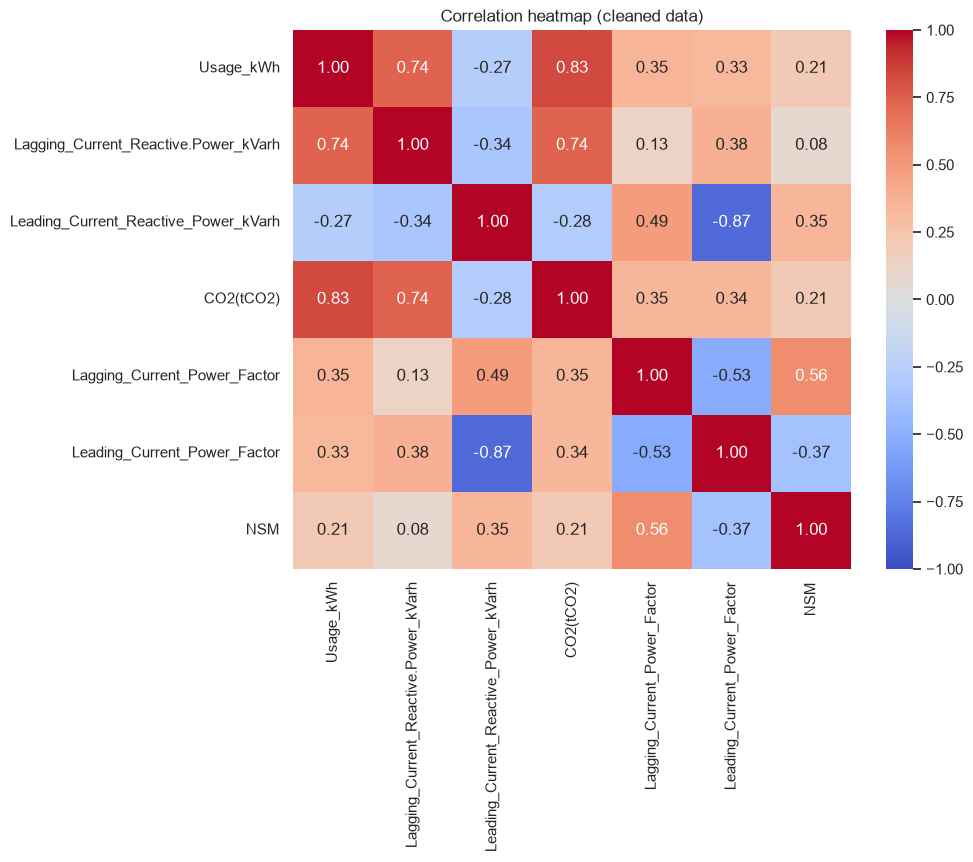

In [52]:
num_cols = ["Usage_kWh", "Lagging_Current_Reactive.Power_kVarh", "Leading_Current_Reactive_Power_kVarh",
            "CO2(tCO2)", "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor", "NSM"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap (cleaned data)")
plt.savefig(f"{FIG_DIR}/correlation.png", bbox_inches="tight")
plt.show()

**Insight:**
- `Usage_kWh`, `CO2(tCO2)` and lagging reactive power are strongly related (0.74 to 0.83). CO2 largely tracks energy usage, so it carries **overlapping information** and could act as a proxy for usage (this matters for the ablation study in section 11).
- Leading reactive power and leading power factor are strongly negatively correlated (−0.87), so they are partly redundant.
- Power factors correlate with time of day (`NSM`), which supports the daily-cycle pattern seen above.
- Correlation only measures *linear* relationships. The time-of-day effect is non-linear (see 4.3 and 4.4), which will matter when choosing models.

In [53]:
rolling_median = df["Usage_kWh"].rolling(5, center=True).median()
spikes = (df["Usage_kWh"] - rolling_median).abs() > 3 * rolling_median.clip(lower=1)
print(f"Isolated spikes flagged: {int(spikes.sum())} of {len(df):,} readings ({spikes.mean():.2%})")

Isolated spikes flagged: 20 of 35,040 readings (0.06%)


In [54]:
df = add_time_features(df)
FEATURES = [c for c in df.columns if c not in ("Date", "Load_Type")]
print(f"{len(FEATURES)} features:")
for f in FEATURES:
    print(" -", f)

12 features:
 - Usage_kWh
 - Lagging_Current_Reactive.Power_kVarh
 - Leading_Current_Reactive_Power_kVarh
 - CO2(tCO2)
 - Lagging_Current_Power_Factor
 - Leading_Current_Power_Factor
 - NSM
 - day_of_week
 - is_weekend
 - is_winter
 - nsm_sin
 - nsm_cos


In [55]:
train, test = time_split(df, cutoff="2018-12-01")
assert train["Date"].max() < test["Date"].min(), "train and test overlap"

pd.DataFrame({
    "From": [train["Date"].min(), test["Date"].min()],
    "To": [train["Date"].max(), test["Date"].max()],
    "Rows": [len(train), len(test)],
}, index=["Train", "Test"])

,From,To,Rows
Train,2018-01-01,2018-11-30 23:45:00,32064
Test,2018-12-01,2018-12-31 23:45:00,2976


In [56]:
pd.DataFrame({
    "Train %": train["Load_Type"].value_counts(normalize=True).mul(100),
    "Test %": test["Load_Type"].value_counts(normalize=True).mul(100),
}).reindex(CLASS_ORDER).round(1)

,Train %,Test %
Load_Type,,
Light_Load,50.9,58.6
Medium_Load,28.0,23.7
Maximum_Load,21.0,17.7


**Note on class shift:** December has relatively more Light Load (about 59%) than the training period (about 51%), likely a quieter holiday month. This is a realistic side effect of testing on future data, and it is one reason a time-based split is a tougher and more honest test than a random one.

In [57]:
X_train, X_test = train[FEATURES], test[FEATURES]

le = LabelEncoder()
y_train = le.fit_transform(train["Load_Type"])
y_test = le.transform(test["Load_Type"])
print("Target encoding:", dict(zip(le.classes_, le.transform(le.classes_))))
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Target encoding: {'Light_Load': np.int64(0), 'Maximum_Load': np.int64(1), 'Medium_Load': np.int64(2)}
X_train: (32064, 12) | X_test: (2976, 12)


In [58]:
baseline = make_pipeline("Logistic Regression", get_models()["Logistic Regression"]).fit(X_train, y_train)
print(classification_report(y_test, baseline.predict(X_test), target_names=le.classes_))

              precision    recall  f1-score   support

  Light_Load       0.96      0.85      0.90      1744
Maximum_Load       0.35      0.39      0.37       528
 Medium_Load       0.33      0.39      0.36       704

    accuracy                           0.66      2976
   macro avg       0.55      0.54      0.54      2976
weighted avg       0.70      0.66      0.68      2976



**Result:** accuracy is about 0.66 and macro F1 about 0.54. The baseline identifies Light Load reasonably well (F1 about 0.90) but is close to guessing for Medium and Maximum (F1 about 0.36).

**Why it struggles:** Logistic Regression draws straight-line boundaries, but the label follows a schedule (a window of hours that changes with the season), and a straight line cannot represent a window. This is why non-linear, tree-based models are tried next.

In [59]:
results, fitted = compare_models(X_train, X_test, y_train, y_test)
results.sort_values("CV Macro F1", ascending=False)

,CV Macro F1,Accuracy,Precision,Recall,Macro F1
Model,,,,,
Random Forest,0.956,0.955,0.945,0.953,0.949
XGBoost,0.956,0.951,0.952,0.935,0.943
LightGBM,0.955,0.951,0.949,0.939,0.944
Decision Tree,0.939,0.917,0.890,0.944,0.912
Logistic Regression,0.757,0.659,0.545,0.545,0.543


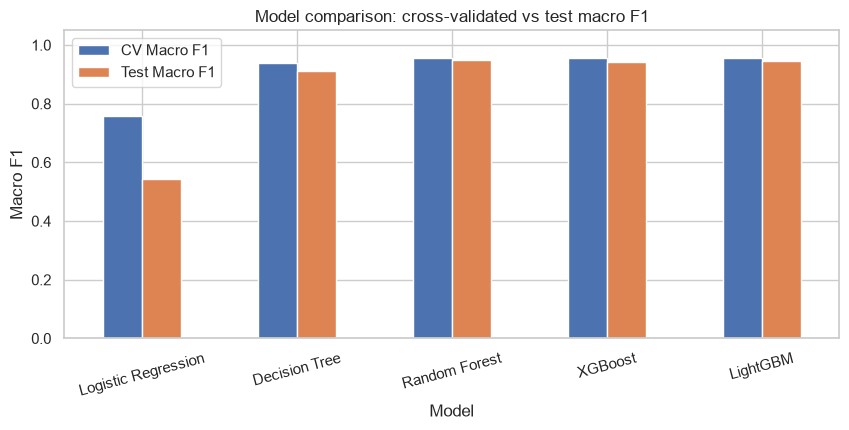

Selected by cross-validation: Random Forest


In [60]:
ax = results[["CV Macro F1", "Macro F1"]].rename(columns={"Macro F1": "Test Macro F1"}).plot(
    kind="bar", figsize=(10, 4), rot=15)
ax.set(title="Model comparison: cross-validated vs test macro F1", ylabel="Macro F1", ylim=(0, 1.05))
plt.savefig(f"{FIG_DIR}/model_comparison.png", bbox_inches="tight")
plt.show()

best_name = results["CV Macro F1"].idxmax()
print(f"Selected by cross-validation: {best_name}")

**Results**
- The three tree ensembles (**Random Forest, LightGBM, XGBoost**) are essentially tied: cross-validated macro F1 of about 0.956, and 0.94 to 0.95 on the test month.
- A single **Decision Tree** is a clear step below (CV 0.939, test 0.912), and the **Logistic Regression** baseline is far behind (CV 0.757, test 0.543).
- For the ensembles, the cross-validated and test scores are close, which suggests the model choice is not overfitting to one period.

**Selection:** Random Forest has the highest CV macro F1 by a hair, so it is selected. With three models this close, the choice among them is not decisive. The main message is that **non-linear ensembles are needed**, and the gap to the baseline is large.

In [61]:
final_pipe = fitted[best_name]
untuned_cv = results.loc[best_name, "CV Macro F1"]

if best_name in PARAM_GRIDS:
    search = RandomizedSearchCV(
        make_pipeline(best_name, get_models()[best_name]), PARAM_GRIDS[best_name],
        n_iter=15, cv=TimeSeriesSplit(n_splits=4), scoring="f1_macro",
        random_state=RANDOM_STATE, n_jobs=1)
    search.fit(X_train, y_train)

    print("Best parameters:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
    print(f"CV macro F1: default {untuned_cv:.3f} -> tuned {search.best_score_:.3f}")
    if search.best_score_ > untuned_cv:
        final_pipe = search.best_estimator_
        print("Keeping the tuned model.")
    else:
        print("Tuning did not improve the CV score, so the default model is kept.")
else:
    print(f"No tuning grid defined for {best_name}; using the default model.")

Best parameters: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None}
CV macro F1: default 0.956 -> tuned 0.959
Keeping the tuned model.


**Result:** tuning raised the cross-validated macro F1 only slightly (about 0.956 to 0.959), so the tuned Random Forest is kept. The gain is small, which suggests the default settings were already close to a good solution and that **the features matter far more than the hyperparameters**. On the test month, the tuned and default models perform the same within noise (macro F1 about 0.95).

              precision    recall  f1-score   support

  Light_Load       0.96      0.96      0.96      1744
Maximum_Load       0.92      0.91      0.92       528
 Medium_Load       0.96      0.96      0.96       704

    accuracy                           0.95      2976
   macro avg       0.95      0.95      0.95      2976
weighted avg       0.95      0.95      0.95      2976



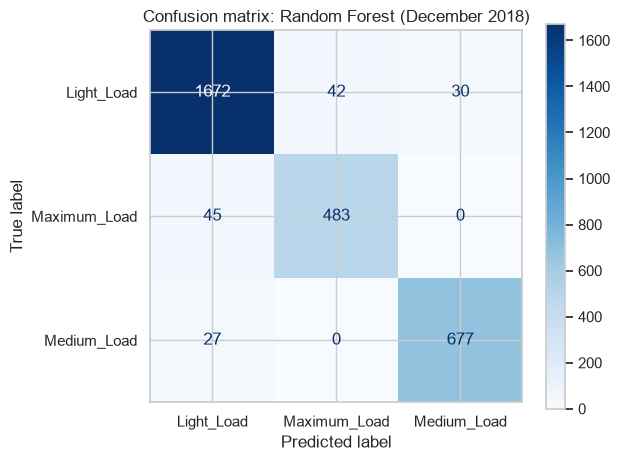

In [62]:
final_pred = final_pipe.predict(X_test)
print(classification_report(y_test, final_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=le.classes_,
                                        cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix: {best_name} (December 2018)")
fig.savefig(f"{FIG_DIR}/confusion_matrix.png", bbox_inches="tight")
plt.show()

**Test-month performance (December 2018):** accuracy **0.95** and macro F1 **0.95**, with every class above 0.90 F1 (Light 0.96, Medium 0.96, Maximum 0.92).

**Reading the confusion matrix**
- Almost all mistakes involve **Light Load**: a few dozen Light readings are predicted as Medium or Maximum, and a similar number of Medium and Maximum readings are predicted as Light.
- **Medium and Maximum are never confused with each other** (zero readings in either direction).
- Maximum Load is the weakest class (F1 0.92). It is also the smallest class in December (about 18% of readings).

**Where the model slips up:** accuracy is close to 100% overnight and through the morning, but falls to about 80 to 86% in the evening (18:00 to 22:00), and Saturdays are the weakest day of the week (about 88% correct). Among the least accurate dates in December are weekend days (the 16th and 22nd), Christmas Day and New Year's Eve, which are likely holidays or irregular days that the schedule features cannot see. A holiday flag is a natural next improvement.

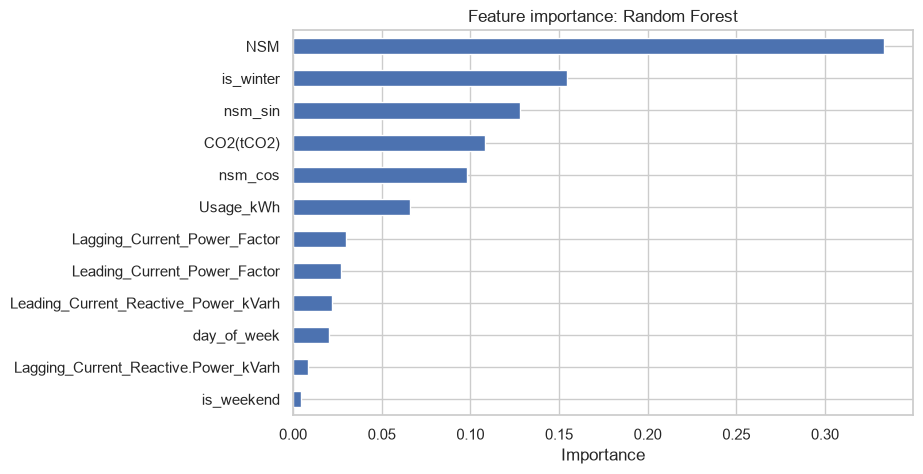

In [63]:
model = final_pipe.named_steps["model"]
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
ax = importance.plot(kind="barh", figsize=(8, 5), title=f"Feature importance: {best_name}")
ax.set_xlabel("Importance")
plt.savefig(f"{FIG_DIR}/feature_importance.png", bbox_inches="tight")
plt.show()

**Insight:** the model leans mostly on **when** the reading happens.
- The three time-of-day features (`NSM`, `nsm_sin`, `nsm_cos`) all encode the same information. Together they account for just over half of the importance (about 56%). Importance is split across correlated features, so read them as one group.
- **`is_winter`** is the most important single feature after `NSM` (about 15%), confirming the seasonal schedule found in section 4.5.
- The electrical readings matter less: `CO2(tCO2)` about 11%, `Usage_kWh` about 7%, and the power factors about 3% each.
- `is_weekend` has very low importance because `day_of_week` already separates Sunday (mostly Light) from Saturday (mixed).

Feature importance shows what the model *uses*, not what *causes* the label. The ablation study below tests this directly.

In [64]:
setups = {
    "All features": FEATURES,
    "Without Usage_kWh": [f for f in FEATURES if f != "Usage_kWh"],
    "Without Usage_kWh & CO2": [f for f in FEATURES if f not in ("Usage_kWh", "CO2(tCO2)")],
    "Schedule only (time, weekday, season)": ["NSM", "day_of_week", "is_weekend", "is_winter", "nsm_sin", "nsm_cos"],
    "Schedule without season": ["NSM", "day_of_week", "is_weekend", "nsm_sin", "nsm_cos"],
}

rows = []
for label, cols in setups.items():
    pipe = make_pipeline(best_name, get_models()[best_name]).fit(X_train[cols], y_train)
    rows.append({"Setup": label, "Features": len(cols), **score_on_test(pipe, X_test[cols], y_test)})
ablation = pd.DataFrame(rows).set_index("Setup").round(3)
ablation

,Features,Accuracy,Precision,Recall,Macro F1
Setup,,,,,
All features,12,0.955,0.945,0.953,0.949
Without Usage_kWh,11,0.932,0.919,0.929,0.924
Without Usage_kWh & CO2,10,0.932,0.917,0.933,0.925
"Schedule only (time, weekday, season)",6,0.862,0.831,0.913,0.858
Schedule without season,5,0.653,0.545,0.544,0.540


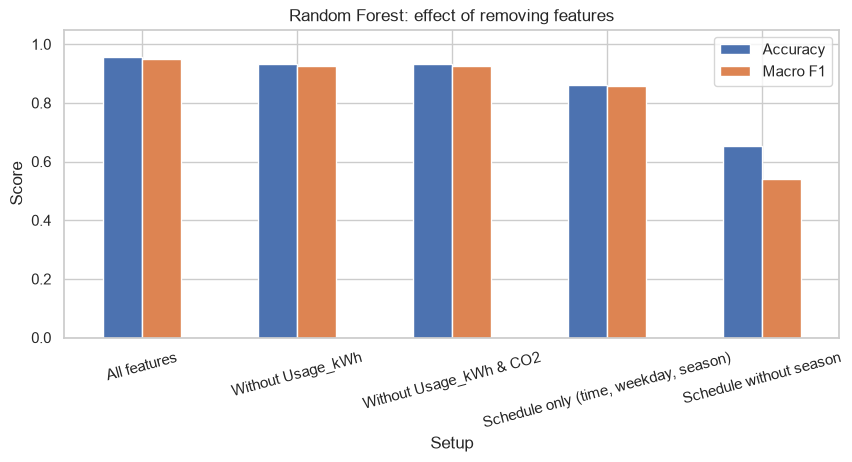

In [65]:
ax = ablation[["Accuracy", "Macro F1"]].plot(kind="bar", figsize=(10, 4), rot=15)
ax.set(title=f"{best_name}: effect of removing features", ylabel="Score", ylim=(0, 1.05))
plt.savefig(f"{FIG_DIR}/feature_ablation.png", bbox_inches="tight")
plt.show()

**Results** (test month, same model with default settings)

| Setup | Macro F1 |
|---|---|
| All features | 0.949 |
| Without `Usage_kWh` | 0.924 |
| Without `Usage_kWh` and `CO2(tCO2)` | 0.925 |
| Schedule only (no electrical readings) | 0.858 |
| Schedule without season | 0.540 |

**What this tells us**
- **No single electrical reading is critical.** Dropping `Usage_kWh`, or `Usage_kWh` and CO2 together, costs only about 2 to 3 points of macro F1. The high score is therefore not simply "usage predicts load type".
- **The schedule explains most of the label.** With no electrical readings at all, time of day, weekday and season reach a macro F1 of about 0.86. The electrical readings add the remaining ~9 points, probably by showing whether the plant is actually running (for example on holidays).
- **Season is essential.** Removing `is_winter` drops macro F1 from about 0.86 to 0.54, because the hours with Maximum Load are different in winter and the model can no longer tell the two seasons apart.

**Caveat:** because the label behaves like a time-of-use schedule, the model is best described as *recovering that schedule from time and season, refined by the plant's actual activity*. It is not discovering a hidden physical relationship in the electrical readings.

In [66]:
joblib.dump(final_pipe, "../models/best_model.joblib")
joblib.dump(le, "../models/label_encoder.joblib")
results.to_csv("../reports/model_comparison.csv")
ablation.to_csv("../reports/feature_ablation.csv")

# Sanity check: the reloaded model reproduces the predictions
reloaded = joblib.load("../models/best_model.joblib")
assert (reloaded.predict(X_test) == final_pred).all()
print("Model and results saved; reload check passed.")

Model and results saved; reload check passed.


### Summary

| | |
|---|---|
| **Problem** | Predict Light, Medium or Maximum load from 15-minute readings of a steel plant |
| **Validation** | Chronological split: January to November for training, **December 2018 as the untouched test month** |
| **Selected model** | Random Forest, chosen by time-series cross-validation and then tuned |
| **Test performance** | Accuracy **0.95**, macro precision 0.95, macro recall 0.95, macro F1 **0.95** (baseline Logistic Regression: macro F1 0.54) |

### Key findings
1. **Data quality mattered.** The raw `NSM` column was wrong in about 3,400 rows and missing in 455, and thousands of power factors were above 100. `NSM` was rebuilt from the timestamp, impossible values were set to missing, and all remaining gaps are imputed using training data only.
2. **The label follows a seasonal schedule.** On weekdays, Maximum Load appears in the late morning in every season, but in the afternoon (about 13:00 to 17:00) only from March to October. In winter the afternoon drops out and the peak moves to the evening (about 17:00 to 20:00). Cyclical time-of-day features and a winter flag were the most valuable engineered features.
3. **Non-linear models are required.** Tree ensembles reach about 0.95 macro F1 against 0.54 for the linear baseline.
4. **The model is robust to losing usage data.** Removing `Usage_kWh` and CO2 costs only 2 to 3 points of macro F1, and the schedule alone reaches about 0.86.
5. **Validation was kept honest.** Time-based split, model selection on training-only cross-validation, and a single evaluation on the test month.

### Limitations
- **One year of data:** the winter pattern is learned from January, February and November and tested on December. A second year would show whether it holds.
- **One test month:** December is quieter than average (59% Light Load against 51% in training), so results for other months may differ.
- **Holidays and irregular days are not modelled**, and they account for many of the remaining errors.
- **The top ensembles tie**, so the choice of Random Forest over LightGBM or XGBoost is not decisive.

